In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
df = pd.read_csv("../results/model_results.csv")
df = df.drop_duplicates("model", keep="last")      # in case a model was run twice, keep its latest row
print(df[["model", "cv_macro_f1_mean", "cv_macro_f1_std", "test_macro_f1", "test_top1", "test_log_loss", "inference_time_s"]])

           model  cv_macro_f1_mean  cv_macro_f1_std  test_macro_f1  test_top1  \
0        hist_gb          0.774113         0.008963       0.778302   0.556212   
1  decision_tree          0.771188         0.009831       0.773838   0.552919   
2         logreg          0.714114         0.008907       0.719449   0.559295   
3    gaussian_nb          0.704185         0.008242       0.709240   0.557466   
4  random_forest          0.783822         0.009054       0.786040   0.554801   
5            knn          0.718724         0.006314       0.716310   0.537396   

   test_log_loss  inference_time_s  
0       0.258325              0.30  
1       0.284991              0.01  
2       0.296954              0.03  
3       0.620957              0.06  
4       0.245882              0.38  
5       0.253007             11.52  


In [3]:
# the models are in the df printed above
# we hv to sort the models using  cv_macro_f1_mean
d = df.sort_values("cv_macro_f1_mean", ascending=False) # so highest cv_macro_f1_Score one comes first
print(d[["model", "cv_macro_f1_mean", "cv_macro_f1_std"]]) # we print the model, the macro f1 score, and the std dev

           model  cv_macro_f1_mean  cv_macro_f1_std
4  random_forest          0.783822         0.009054
0        hist_gb          0.774113         0.008963
1  decision_tree          0.771188         0.009831
5            knn          0.718724         0.006314
2         logreg          0.714114         0.008907
3    gaussian_nb          0.704185         0.008242


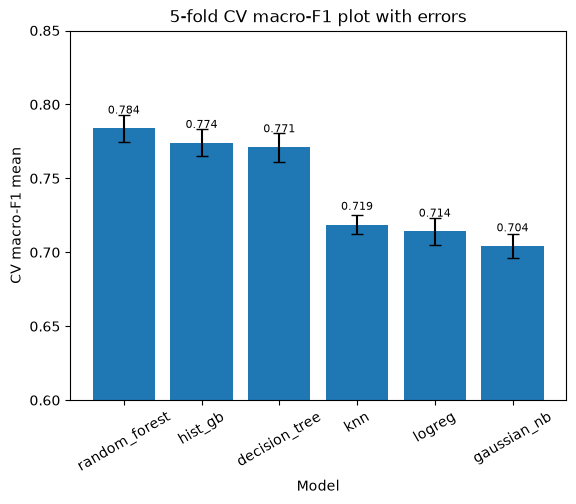

In [7]:
# now we plot the cv macro-f1 with error bars
plt.bar(d["model"], d["cv_macro_f1_mean"], yerr=d["cv_macro_f1_std"], capsize=4)
plt.title("5-fold CV macro-F1 plot with errors")
plt.ylabel("CV macro-F1 mean")
plt.xlabel("Model")
plt.xticks(rotation=30) #so that in the x label the names are visible clearly and dont overlap
plt.ylim(0.6, 0.85)
for i, v in enumerate(d["cv_macro_f1_mean"]):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
plt.savefig("../results/figures/cv_macro_f1.png", dpi=150, bbox_inches="tight")
plt.show()